# 04 · Federated robustness: a dishonest hospital and the server-side defence

**Locked method (from notebook 03):** federated XGBoost bagging with **equal client scaling** (each client's trees × 1/n).
3 sites: 0.955 macro-F1 (pooled 0.958), 0.89 false alarms/h · unseen site C: 0.948 · Dirichlet α 0.1 / 0.5 / 5: 0.867 / 0.945 / 0.950.

**Question here:** what happens if one hospital (or its compromised training server) sends bad updates — and can the server stop it without seeing anyone's data?

| Attack (by one site, `MAL_SITE`) | What it does | Goal |
|---|---|---|
| `label_flip` | relabels its **exfiltration** windows as benign before training | targeted: make the global model miss exfiltration (hide its own attack) |
| `random_labels` | shuffles all its labels | untargeted: degrade the model |
| `flip_amplify` | label flip **and** multiplies its trees' leaf values × 5 | targeted + tries to dominate the average |

| Defence (server side, no raw data) | How |
|---|---|
| `gate-median` · peer validation | each candidate update is scored by the **other** sites on their own validation windows (class-balanced log-loss before vs after adding it); rejected if the **median** peer says it got worse by more than `TOL` |
| `gate-kofn` · peer validation, Byzantine-aware | same scores, but accepted if at least **n − 1 − f** peers approve (f = assumed attackers = 1). With 3 sites: one approval suffices, so an attacker cannot veto honest updates, while its own update still needs an honest peer's approval |
| `clip` · magnitude clipping | an update whose size (RMS change of scores on peers' validation windows) is more than `CLIP_K` × the round's median is scaled down |
| `gate-kofn+clip` | both |

Reported: macro-F1, **exfiltration recall** (the attack target), false alarms/h, how often malicious vs honest updates were rejected or clipped. Logged to MLflow (`vitalgate-federated`, `tags.stage = "fl_robustness"`).

Tested on purpose: with 3 sites the attacker is one of the two peers judging every honest update, and its own validation labels are poisoned too. A plain median vote lets it veto honest updates — `gate-kofn` is the fix (found on the synthetic test run: median gate + random-label attacker rejected 57% of honest updates).

Runtime ≈ 30–50 min; `FAST = True` ≈ 10 min.

In [1]:
# 0 · Setup
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, matthews_corrcoef, average_precision_score, recall_score
import xgboost as xgb
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")

FAST = False

SEEDS = [0] if FAST else [0, 1]
MAL_SITE = "B"                       # the dishonest hospital
TARGET = "exfiltration"              # class the targeted attacker wants hidden
AMP = 5.0                            # leaf-value multiplier for flip_amplify
TOL, CLIP_K = 0.002, 2.0             # gate tolerance (balanced log-loss) and clipping factor
F_ASSUMED = 1                        # number of dishonest sites the k-of-n gate is built to tolerate
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, MODELS = REPO / "data" / "processed", REPO / "models"
REP = REPO / "reports" / "fl_robustness"; REP.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO / "src"))
import tracking, mlflow
tracking.use_experiment("vitalgate-federated")
print("xgboost", xgb.__version__, "| session", tracking.SESSION)

xgboost 3.4.1 | session 20261114-233418


## 1 · Data and metrics (same as notebooks 02–03)

In [2]:
CFG = json.loads((MODELS / "xgb_config.json").read_text(encoding="utf-8"))
FEATURES, BEST, TAU = CFG["features"], CFG["best_params"], CFG.get("tau")
ROLL_BASE = CFG["rolling"]["base"]; ROLL_FEATS = [f"{b}_roll3" for b in ROLL_BASE]
RULE_CLASS = CFG["rule_class"]
win = pd.read_parquet(PROC / "windows_v2.parquet")
import features as FV
d = FV.add_history(win[win["label_class"] != RULE_CLASS].reset_index(drop=True), "split_run")   # v3
le = LabelEncoder().fit(d["label_class"]); CLS = list(le.classes_); K = len(CLS)
BEN, REC, TGT = CLS.index("benign"), CLS.index("recon"), CLS.index(TARGET)
y = le.transform(d["label_class"]); X = d[FEATURES].to_numpy(np.float32)
TR, VA, TE = [(d["split_run"] == p).values for p in ("train", "val", "test")]
SITES = sorted(d["site"].unique()); MAL = SITES.index(MAL_SITE)
site_mask = {s: (d["site"] == s).values for s in SITES}

def hours(frame, cap=60.0):
    t = frame.sort_values(["client_ip", "window_start"])
    return t.groupby("client_ip")["window_start"].diff().fillna(2.0).clip(upper=cap).sum() / 3600.0
H_VA, H_TE = hours(d[VA]), hours(d[TE])

def metrics(yt, prob, h):
    pred = prob.argmax(1); keep = yt != REC
    return dict(macro_F1=f1_score(yt, pred, labels=range(K), average="macro", zero_division=0),
                macro_F1_no_recon=f1_score(yt[keep], pred[keep], labels=[i for i in range(K) if i != REC], average="macro", zero_division=0),
                recall_target=recall_score(yt == TGT, pred == TGT, zero_division=0),
                F1_target=f1_score(yt == TGT, pred == TGT, zero_division=0),
                FP_per_wallclock_h=((pred != BEN) & (yt == BEN)).sum() / h,
                PR_AUC=average_precision_score((yt != BEN).astype(int), 1 - prob[:, BEN]))
print(f"{len(FEATURES)} features | malicious site {MAL_SITE} | target class {TARGET}")

83 features | malicious site B | target class exfiltration


## 2 · Lock the federated method

In [3]:
FED = dict(method="FedXgb bagging, equal client scaling (1/n)", agg="equal", local_trees=10, max_rounds=40 if FAST else 80, patience=6,
           xgb=dict(max_depth=int(BEST["depth"]), eta=float(BEST["lr"]), subsample=0.8, colsample_bytree=0.8, class_weights=BEST.get("weights")),
           round0=["class counts -> global prior + class weights"],
           results_notebook03={"P1_3_sites_macroF1": 0.955, "P1_FP_per_h": 0.893, "centralised_macroF1": 0.958,
                               "unseen_site_C_macroF1": 0.948, "dirichlet_macroF1": {"0.1": 0.867, "0.5": 0.945, "5.0": 0.950}})
(MODELS / "fed_config.json").write_text(json.dumps(FED, indent=2), encoding="utf-8")
LOCAL_TREES, MAX_ROUNDS, PATIENCE = FED["local_trees"], FED["max_rounds"], FED["patience"]
print(json.dumps(FED, indent=1)[:400], "...")

{
 "method": "FedXgb bagging, equal client scaling (1/n)",
 "agg": "equal",
 "local_trees": 10,
 "max_rounds": 80,
 "patience": 6,
 "xgb": {
  "max_depth": 4,
  "eta": 0.05,
  "subsample": 0.8,
  "colsample_bytree": 0.8,
  "class_weights": "sqrt"
 },
 "round0": [
  "class counts -> global prior + class weights"
 ],
 "results_notebook03": {
  "P1_3_sites_macroF1": 0.926,
  "P1_FP_per_h": 1.255,
  " ...


## 3 · Federated training with attacks and defences

In [4]:
def xgb_params(seed):
    return dict(objective="multi:softprob", num_class=K, max_depth=FED["xgb"]["max_depth"], eta=FED["xgb"]["eta"],
                subsample=0.8, colsample_bytree=0.8, tree_method="hist", seed=int(seed), nthread=os.cpu_count() or 4)

def dmat(Xa, ya=None, w=None, margin=None):
    if margin is None: return xgb.DMatrix(Xa, label=ya, weight=w)
    try:    return xgb.DMatrix(Xa, label=ya, weight=w, base_margin=margin)
    except Exception: return xgb.DMatrix(Xa, label=ya, weight=w, base_margin=margin.ravel())

def contrib(b, Xa):
    return b.predict(dmat(Xa, margin=np.zeros((len(Xa), K), np.float32)), output_margin=True).reshape(len(Xa), K)

def softmax(m):
    e = np.exp(m - m.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def balanced_logloss(yv, P):
    p = np.clip(P[np.arange(len(yv)), yv], 1e-7, 1.0)
    return float(np.mean([-np.log(p[yv == c]).mean() for c in np.unique(yv)]))

def poison(yy, attack, rng):
    yy = yy.copy()
    if attack in ("label_flip", "flip_amplify"): yy[yy == TGT] = BEN
    elif attack == "random_labels": yy = rng.permutation(yy)
    return yy

def build_clients(attack, seed):
    rng = np.random.default_rng(seed)
    clients, cvals = [], []
    for i, s in enumerate(SITES):
        ytr, yva = y[TR & site_mask[s]], y[VA & site_mask[s]]
        if i == MAL and attack != "none":
            ytr, yva = poison(ytr, attack, rng), poison(yva, attack, rng)     # attacker is consistent: its own val is poisoned too
        clients.append((X[TR & site_mask[s]], ytr)); cvals.append((X[VA & site_mask[s]], yva))
    return clients, cvals

def fed_robust(clients, cvals, seed, amp=None, gate=None, clip=False, log=True):
    # gate: None | "median" | "kofn"
    n = len(clients)
    counts = sum(np.bincount(yc, minlength=K) for _, yc in clients)
    prior = np.log(np.maximum(counts, 1) / counts.sum()).astype(np.float32)
    w_cls = (counts.max() / np.maximum(counts, 1)) ** 0.5 if FED["xgb"]["class_weights"] == "sqrt" else np.ones(K)
    m_tr = [np.tile(prior, (len(yc), 1)) for _, yc in clients]
    m_cv = [np.tile(prior, (len(yv), 1)) for _, yv in cvals]
    evals = {"val": (X[VA], y[VA], H_VA), "test": (X[TE], y[TE], H_TE)}
    m_ev = {k: np.tile(prior, (len(v[1]), 1)) for k, v in evals.items()}
    st = {k: np.zeros(n) for k in ("offered", "rejected", "clipped")}
    best, since = dict(f1=-1, round=0, m=None), 0
    for t in range(1, MAX_ROUNDS + 1):
        cands = []
        for i, (Xc, yc) in enumerate(clients):
            b = xgb.train(xgb_params(seed * 1000 + t * 10 + i), dmat(Xc, yc, w_cls[yc], m_tr[i]), LOCAL_TREES)
            a = (amp or {}).get(i, 1.0)
            cands.append((i, b, a, [a * contrib(b, cvals[j][0]) for j in range(n)]))
        norms = np.array([np.sqrt(np.mean(np.concatenate([dv[j].ravel() for j in range(n) if j != i]) ** 2)) for i, _, _, dv in cands])
        med = np.median(norms); accepted = []
        for (i, b, a, dv), nm in zip(cands, norms):
            st["offered"][i] += 1; sc = 1.0 / n
            if clip and nm > CLIP_K * med:
                sc *= CLIP_K * med / nm; st["clipped"][i] += 1
            if gate:
                deltas = [balanced_logloss(cvals[j][1], softmax(m_cv[j] + sc * dv[j])) - balanced_logloss(cvals[j][1], softmax(m_cv[j]))
                          for j in range(n) if j != i]
                if gate == "median":
                    ok = np.median(deltas) <= TOL
                else:                                   # k-of-n: need at least n-1-f approving peers
                    need = max(1, (n - 1) - F_ASSUMED)
                    ok = np.sum(np.array(deltas) <= TOL) >= need
                if not ok:
                    st["rejected"][i] += 1; continue
            accepted.append((i, b, a, sc, dv))
        for i, b, a, sc, dv in accepted:
            for k, (Xc, _) in enumerate(clients): m_tr[k] += sc * a * contrib(b, Xc)
            for k in range(n): m_cv[k] += sc * dv[k]
            for key, (Xe, _, _) in evals.items(): m_ev[key] += sc * a * contrib(b, Xe)
        r = metrics(evals["val"][1], softmax(m_ev["val"]), evals["val"][2])
        if log and mlflow.active_run():
            tracking.log_metrics({"val_macro_F1": r["macro_F1"], "val_recall_target": r["recall_target"],
                                  "accepted_updates": len(accepted)}, step=t)
        if r["macro_F1"] > best["f1"] + 1e-4:
            best = dict(f1=r["macro_F1"], round=t, m={k: v.copy() for k, v in m_ev.items()}); since = 0
        else:
            since += 1
            if since >= PATIENCE: break
    test = metrics(y[TE], softmax(best["m"]["test"]), H_TE)
    honest = [i for i in range(n) if i != MAL]
    return dict(best_round=best["round"], rounds_run=t, **test,
                mal_rejected_rate=st["rejected"][MAL] / st["offered"][MAL], honest_rejected_rate=st["rejected"][honest].sum() / st["offered"][honest].sum(),
                mal_clipped_rate=st["clipped"][MAL] / st["offered"][MAL], honest_clipped_rate=st["clipped"][honest].sum() / st["offered"][honest].sum())

## 4 · Run the grid: attack × defence × seed

In [5]:
ATTACKS = ["none", "label_flip", "random_labels", "flip_amplify"]
DEFENCES = {"none": dict(), "clip": dict(clip=True), "gate-median": dict(gate="median"),
            "gate-kofn": dict(gate="kofn"), "gate-kofn+clip": dict(gate="kofn", clip=True)}
rows = []
for seed in SEEDS:
    for attack in ATTACKS:
        clients, cvals = build_clients(attack, seed)
        amp = {MAL: AMP} if attack == "flip_amplify" else None
        for dname, dflags in DEFENCES.items():
            with tracking.run(f"FL robustness · {attack} · {dname} · seed {seed}",
                              params={"attack": attack, "defence": dname, "malicious_site": MAL_SITE if attack != "none" else "-",
                                      "target": TARGET, "amp": AMP if amp else 1.0, "tol": TOL, "clip_k": CLIP_K, "f_assumed": F_ASSUMED, "seed": seed, "agg": "equal"},
                              tags={"stage": "fl_robustness", "attack": attack, "defence": dname}):
                r = fed_robust(clients, cvals, seed, amp=amp, **dflags)
                tracking.log_metrics({k: v for k, v in r.items()}, prefix="")
            rows.append(dict(seed=seed, attack=attack, defence=dname, **r))
            print(f"seed {seed} | {attack:13s} | {dname:9s} | macro-F1 {r['macro_F1']:.3f} | {TARGET} recall {r['recall_target']:.3f} "
                  f"| mal rejected {r['mal_rejected_rate']:.2f} | honest rejected {r['honest_rejected_rate']:.2f}")
R = pd.DataFrame(rows)
R.to_csv(REP / "fl_robustness_all.csv", index=False, encoding="utf-8-sig")

seed 0 | none          | none      | macro-F1 0.954 | exfiltration recall 0.788 | mal rejected 0.00 | honest rejected 0.00
seed 0 | none          | clip      | macro-F1 0.954 | exfiltration recall 0.788 | mal rejected 0.00 | honest rejected 0.00
seed 0 | none          | gate-median | macro-F1 0.953 | exfiltration recall 0.799 | mal rejected 0.00 | honest rejected 0.46
seed 0 | none          | gate-kofn | macro-F1 0.954 | exfiltration recall 0.788 | mal rejected 0.00 | honest rejected 0.00
seed 0 | none          | gate-kofn+clip | macro-F1 0.954 | exfiltration recall 0.788 | mal rejected 0.00 | honest rejected 0.00
seed 0 | label_flip    | none      | macro-F1 0.943 | exfiltration recall 0.625 | mal rejected 0.00 | honest rejected 0.00
seed 0 | label_flip    | clip      | macro-F1 0.943 | exfiltration recall 0.625 | mal rejected 0.00 | honest rejected 0.00
seed 0 | label_flip    | gate-median | macro-F1 0.953 | exfiltration recall 0.778 | mal rejected 0.81 | honest rejected 0.12
seed 0 

## 5 · Results

macro-F1 (split_run test):


defence,none,clip,gate-median,gate-kofn,gate-kofn+clip
attack,,,,,
none,0.955,0.955,0.953,0.955,0.955
label_flip,0.944,0.944,0.953,0.953,0.953
random_labels,0.947,0.947,0.904,0.952,0.954
flip_amplify,0.831,0.901,0.949,0.950,0.953


exfiltration recall — the targeted attacker wants this low:


defence,none,clip,gate-median,gate-kofn,gate-kofn+clip
attack,,,,,
none,0.792,0.792,0.795,0.792,0.792
label_flip,0.637,0.637,0.766,0.766,0.766
random_labels,0.720,0.720,0.478,0.761,0.778
flip_amplify,0.010,0.323,0.761,0.763,0.770


false alarms per wall-clock client-hour:


defence,none,clip,gate-median,gate-kofn,gate-kofn+clip
attack,,,,,
none,0.88,0.88,1.13,0.88,0.88
label_flip,0.50,0.50,0.71,0.70,0.70
random_labels,0.68,0.68,0.08,0.66,0.84
flip_amplify,0.71,0.67,0.95,0.88,0.77


share of the malicious site's updates rejected | honest sites' updates rejected:


malicious rejected                                            \
defence                     none clip gate-median gate-kofn gate-kofn+clip   
attack                                                                       
none                         0.0  0.0        0.00      0.00           0.00   
label_flip                   0.0  0.0        0.76      0.76           0.76   
random_labels                0.0  0.0        0.88      0.92           0.60   
flip_amplify                 0.0  0.0        0.97      0.97           0.89   

              honest rejected                                            
defence                  none clip gate-median gate-kofn gate-kofn+clip  
attack                                                                   
none                      0.0  0.0        0.34       0.0            0.0  
label_flip                0.0  0.0        0.06       0.0            0.0  
random_labels             0.0  0.0        0.63       0.0            0.0  
flip_amplify              0.0  0.0        0.14       0.0            0.0

share clipped (malicious | honest):


malicious clipped                                            \
defence                    none clip gate-median gate-kofn gate-kofn+clip   
attack                                                                      
none                        0.0  0.0         0.0       0.0           0.00   
label_flip                  0.0  0.0         0.0       0.0           0.05   
random_labels               0.0  0.0         0.0       0.0           0.84   
flip_amplify                0.0  1.0         0.0       0.0           1.00   

              honest clipped                                            
defence                 none clip gate-median gate-kofn gate-kofn+clip  
attack                                                                  
none                     0.0  0.0         0.0       0.0            0.0  
label_flip               0.0  0.0         0.0       0.0            0.0  
random_labels            0.0  0.0         0.0       0.0            0.0  
flip_amplify             0.0  0.0         0.0       0.0            0.0

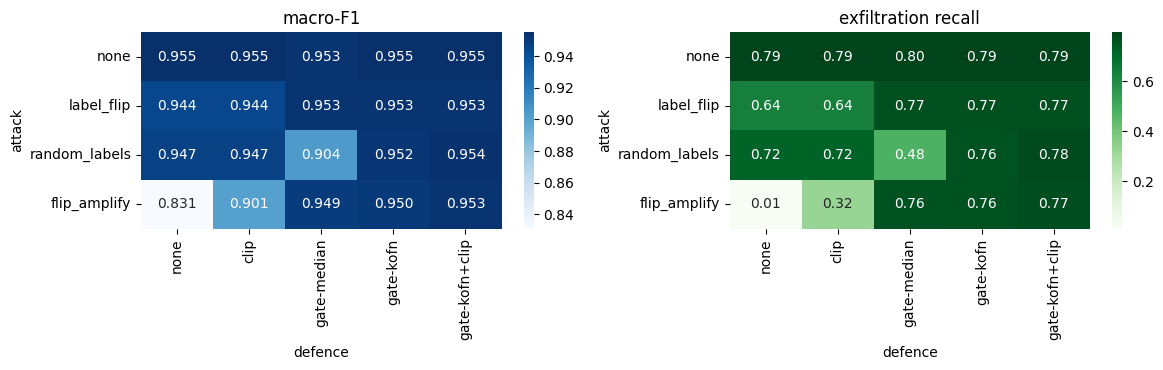

change vs. no attack, no defence:


Δ macro-F1 vs clean  \
none          none                          0.000   
              clip                          0.000   
              gate-median                  -0.002   
              gate-kofn                     0.000   
              gate-kofn+clip                0.000   
label_flip    none                         -0.011   
              clip                         -0.011   
              gate-median                  -0.002   
              gate-kofn                    -0.002   
              gate-kofn+clip               -0.002   
random_labels none                         -0.008   
              clip                         -0.008   
              gate-median                  -0.050   
              gate-kofn                    -0.003   
              gate-kofn+clip               -0.001   
flip_amplify  none                         -0.124   
              clip                         -0.054   
              gate-median                  -0.006   
              gate-kofn                    -0.005   
              gate-kofn+clip               -0.002   

                              Δ exfiltration recall vs clean  
none          none                                     0.000  
              clip                                     0.000  
              gate-median                              0.003  
              gate-kofn                                0.000  
              gate-kofn+clip                           0.000  
label_flip    none                                    -0.155  
              clip                                    -0.155  
              gate-median                             -0.026  
              gate-kofn                               -0.026  
              gate-kofn+clip                          -0.026  
random_labels none                                    -0.072  
              clip                                    -0.072  
              gate-median                             -0.314  
              gate-kofn                               -0.031  
              gate-kofn+clip                          -0.014  
flip_amplify  none                                    -0.782  
              clip                                    -0.469  
              gate-median                             -0.031  
              gate-kofn                               -0.029  
              gate-kofn+clip                          -0.022

In [6]:
def pivot(col, fmt=3):
    t = R.groupby(["attack", "defence"])[col].mean().unstack("defence")
    return t.reindex(index=ATTACKS, columns=list(DEFENCES)).round(fmt)

print("macro-F1 (split_run test):"); MF1 = pivot("macro_F1"); display(MF1)
print(f"{TARGET} recall — the targeted attacker wants this low:"); RT = pivot("recall_target"); display(RT)
print("false alarms per wall-clock client-hour:"); display(pivot("FP_per_wallclock_h", 2))
print("share of the malicious site's updates rejected | honest sites' updates rejected:")
display(pd.concat({"malicious rejected": pivot("mal_rejected_rate", 2), "honest rejected": pivot("honest_rejected_rate", 2)}, axis=1))
print("share clipped (malicious | honest):")
display(pd.concat({"malicious clipped": pivot("mal_clipped_rate", 2), "honest clipped": pivot("honest_clipped_rate", 2)}, axis=1))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(MF1, annot=True, fmt=".3f", cmap="Blues", ax=ax[0]); ax[0].set_title("macro-F1")
sns.heatmap(RT, annot=True, fmt=".2f", cmap="Greens", ax=ax[1]); ax[1].set_title(f"{TARGET} recall")
plt.tight_layout(); plt.savefig(REP / "fl_robustness_heatmaps.png"); plt.show()

clean = R[(R.attack == "none") & (R.defence == "none")][["macro_F1", "recall_target"]].mean()
summ = (R.groupby(["attack", "defence"])[["macro_F1", "recall_target"]].mean() - clean).round(3)
summ.columns = ["Δ macro-F1 vs clean", f"Δ {TARGET} recall vs clean"]
print("change vs. no attack, no defence:"); display(summ.reindex(pd.MultiIndex.from_product([ATTACKS, list(DEFENCES)])))

## 6 · Save

In [7]:
for name, t in {"macro_F1": MF1, "recall_target": RT}.items():
    t.to_csv(REP / f"fl_robustness_{name}.csv", encoding="utf-8-sig")
with tracking.run("FL robustness summary", tags={"stage": "fl_robustness_summary"}):
    tracking.log_files(REP / "fl_robustness_all.csv", REP / "fl_robustness_macro_F1.csv", REP / "fl_robustness_recall_target.csv",
                       REP / "fl_robustness_heatmaps.png", MODELS / "fed_config.json")
print("saved to", REP)

saved to c:\Users\rashi\Desktop\VitalGate Project Code\reports\fl_robustness
